## Import and Reading Data

In [1]:
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import LeakyReLU

## Load Train and Test Datasets

In [2]:
# Load training data
df_train = pd.read_csv('D:/X-AI PROJECT/0_Datasets/NSL-KDD dataset/nsl-kdd/train.csv')

In [3]:
# Load testing data
df_test = pd.read_csv('D:/X-AI PROJECT/0_Datasets/NSL-KDD dataset/nsl-kdd/test.csv')

In [4]:
X_train = df_train.drop(['binary_attack'], axis=1)  # Features
y_train = df_train['binary_attack']  # Target variable

In [5]:
X_test = df_test.drop(['binary_attack'], axis=1)  # Features
y_test = df_test['binary_attack']  # Target variable

In [6]:
X_train, X_train_test, y_train, y_train_test = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

-----
## Create Model and Train Model

In [7]:
X_train.shape,y_train.shape

((100778, 42), (100778,))

In [8]:
X_train_test.shape, y_train_test.shape

((25195, 42), (25195,))

In [9]:
X_test.shape,y_test.shape

((22544, 42), (22544,))

In [10]:
%%time

# Define the model
model = Sequential()
model.add(Dense(128, input_dim=X_train.shape[1], activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(256, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(128, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(32, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))

C:\Users\AKASH SENANI\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


CPU times: total: 562 ms
Wall time: 587 ms


In [11]:
# Compile the model with learning rate
optimizer = Adam(learning_rate=0.001)
model.compile(loss='binary_crossentropy', optimizer=optimizer, metrics=['accuracy'])

In [12]:
# Define early stopping
monitor = tf.keras.callbacks.ReduceLROnPlateau(monitor="loss",factor=0.5,mode="min",patience=10,verbose=1,min_lr=1e-7)
checkpoint = ModelCheckpoint('Saved_Models/NSL-KDD_DNN.keras', monitor='val_loss', save_best_only=True)

In [13]:
# Train the model
history = model.fit(X_train, y_train, validation_data=(X_train_test, y_train_test), epochs=100, batch_size=512, callbacks=[monitor, checkpoint])

Epoch 1/100
197/197 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.8759 - loss: 0.3125 - val_accuracy: 0.9222 - val_loss: 0.2254 - learning_rate: 0.0010
Epoch 2/100
197/197 ━━━━━━━━━━━━━━━━━━━━ 7s 33ms/step - accuracy: 0.9374 - loss: 0.1722 - val_accuracy: 0.9206 - val_loss: 0.2582 - learning_rate: 0.0010
Epoch 3/100
197/197 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - accuracy: 0.9514 - loss: 0.1355 - val_accuracy: 0.9392 - val_loss: 0.2141 - learning_rate: 0.0010
Epoch 4/100
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.9605 - loss: 0.1154 - val_accuracy: 0.9493 - val_loss: 0.1845 - learning_rate: 0.0010
Epoch 5/100
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9643 - loss: 0.1034 - val_accuracy: 0.9505 - val_loss: 0.1988 - learning_rate: 0.0010
Epoch 6/100
197/197 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.9667 - loss: 0.0974 - val_accuracy: 0.9497 - val_loss: 0.1685 - learning_rate: 0.0010
Epoch 7/100
197/197 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.9705 - 

In [14]:
# Load the best saved model
best_model = load_model('Saved_Models/NSL-KDD_DNN.keras')

In [15]:
pred = model.predict(X_train_test)

788/788 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step


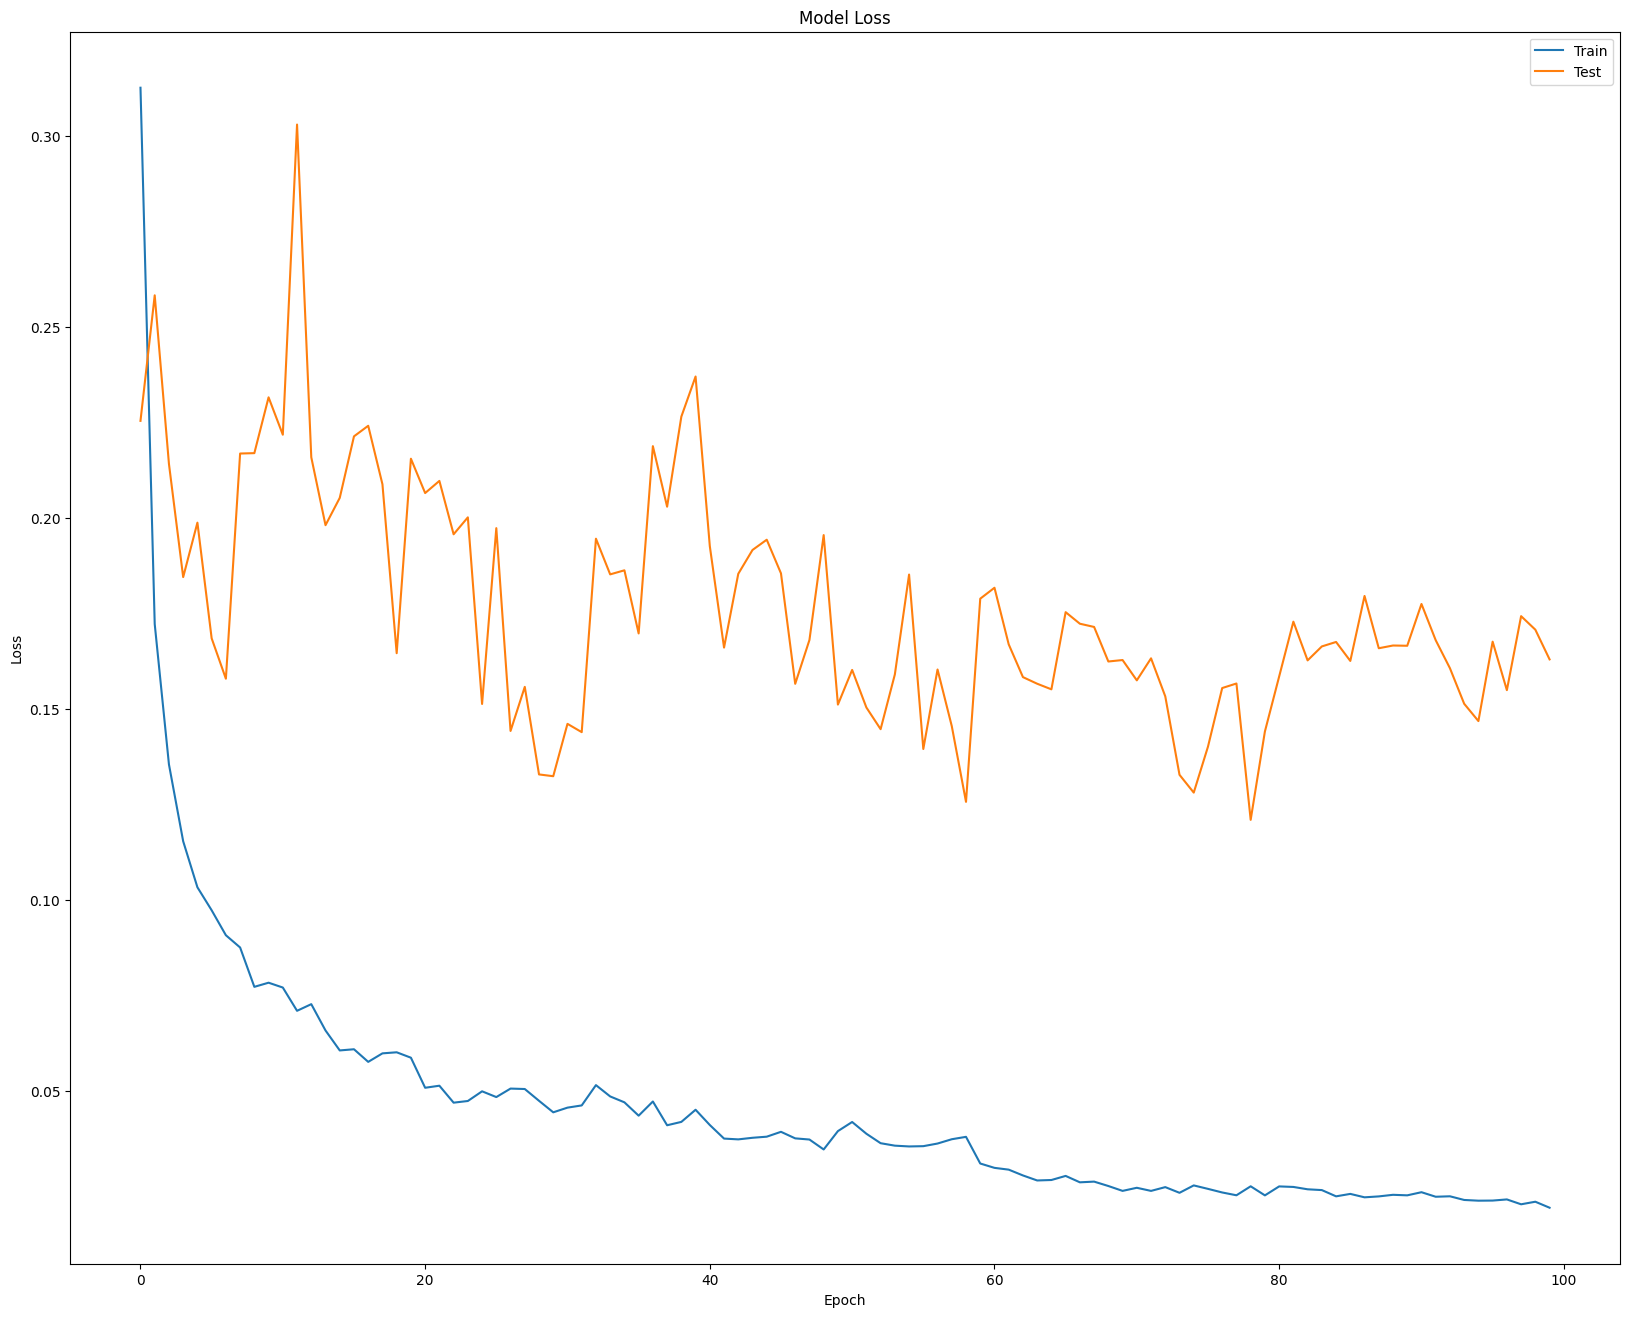

In [16]:
fig, ax = plt.subplots(figsize=(20, 16))

ax.plot(history.history['loss'], label='train')
ax.plot(history.history['val_loss'], label='test')
ax.set_title('Model Loss')
ax.set_ylabel('Loss')
ax.set_xlabel('Epoch')
ax.legend(['Train', 'Test'], loc='upper right')
plt.show()

## Results

### Training

In [17]:
threshold = 0.5  # Adjust the threshold as needed
pred = (pred > threshold).astype(int)

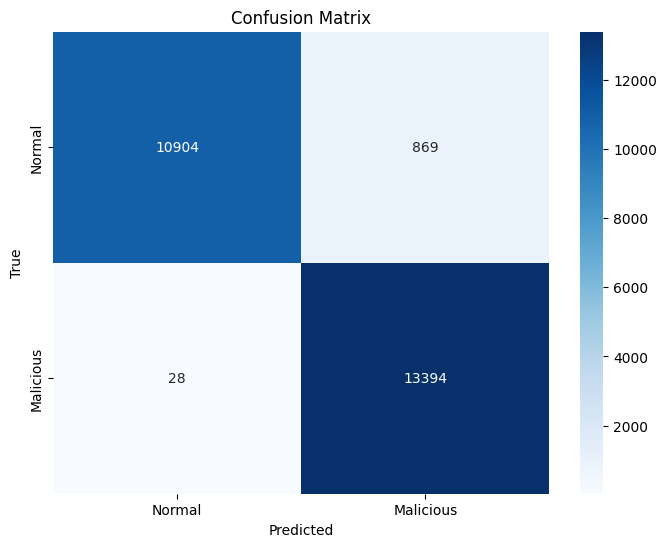

In [18]:
# Compute confusion matrix
cm = confusion_matrix(y_train_test, pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal', 'Malicious'], 
            yticklabels=['Normal', 'Malicious'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [19]:
accuracy = accuracy_score(y_train_test, pred)
precision = precision_score(y_train_test, pred)
recall = recall_score(y_train_test, pred)
f1 = f1_score(y_train_test, pred)

print("Accuracy:   {:.2%}".format(accuracy))
print("Precision:  {:.2%}".format(precision))
print("Recall:     {:.2%}".format(recall))
print("F1-score:   {:.2%}".format(f1))

Accuracy:   96.44%
Precision:  93.91%
Recall:     99.79%
F1-score:   96.76%


### with Test Dataset

In [20]:
pred_test = model.predict(X_test)

705/705 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step


In [21]:
threshold = 0.5  # Adjust the threshold as needed
pred_test = (pred_test > threshold).astype(int)

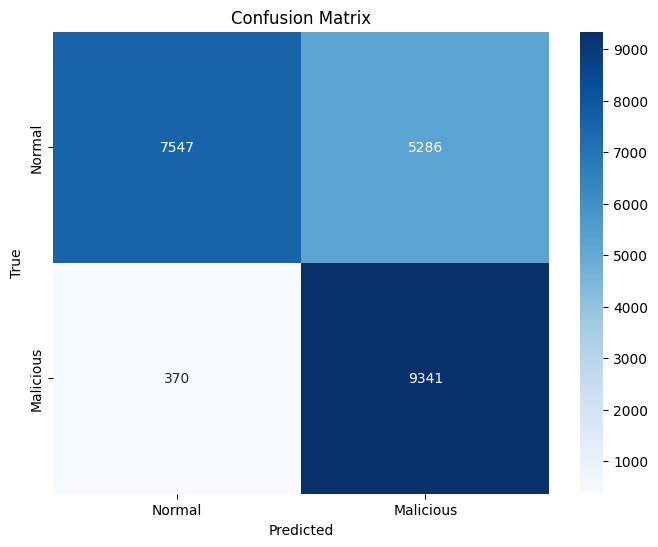

In [22]:
# Compute confusion matrix
cm = confusion_matrix(y_test, pred_test)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Normal', 'Malicious'], 
            yticklabels=['Normal', 'Malicious'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

In [23]:
# Compute accuracy
accuracy = accuracy_score(y_test, pred_test)
precision = precision_score(y_test, pred_test)
recall = recall_score(y_test, pred_test)
f1 = f1_score(y_test, pred_test)

print("Accuracy:   {:.2%}".format(accuracy))
print("Precision:  {:.2%}".format(precision))
print("Recall:     {:.2%}".format(recall))
print("F1-score:   {:.2%}".format(f1))

Accuracy:   74.91%
Precision:  63.86%
Recall:     96.19%
F1-score:   76.76%


In [24]:
import json
import numpy as np
import pandas as pd

metrics = {
    "dataset": "NSL-KDD",
    "model": "DNN",
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1)
}

with open("Saved_Models/NSL-KDD_DNN_metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

print("NSL-KDD DNN metrics saved successfully.")

NSL-KDD DNN metrics saved successfully.


In [25]:
probabilities = model.predict(X_test)
probabilities = probabilities.flatten()

predictions = (probabilities >= 0.5).astype(int)

prediction_df = pd.DataFrame({
    "Actual": np.array(y_test).flatten(),
    "Predicted": predictions,
    "Probability": probabilities
})

prediction_df.to_csv(
    "Saved_Models/NSL-KDD_DNN_predictions.csv",
    index=False
)

print("NSL-KDD DNN predictions saved successfully.")

705/705 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
NSL-KDD DNN predictions saved successfully.
